# Determination of the critical porperties of a 2D Ising Model on honeycomb lattice

In [14]:
# LIBRARIES
import Ising_tools
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import time

In [9]:
'''# METROPOLIS STEPS

T = np.arange(0.1, 5.1, 0.1)  # temperature range
metropolis_steps = L**2               # number of Metropolis steps

for temperature in tqdm(T):
    for i in range(metropolis_steps):
        spin_matrix = Ising_tools.metropolis(spin_matrix, temperature)
    pass'''

'# METROPOLIS STEPS\n\nT = np.arange(0.1, 5.1, 0.1)  # temperature range\nmetropolis_steps = L**2               # number of Metropolis steps\n\nfor temperature in tqdm(T):\n    for i in range(metropolis_steps):\n        spin_matrix = Ising_tools.metropolis(spin_matrix, temperature)\n    pass'

100%|██████████| 1000/1000 [04:50<00:00,  3.44it/s]


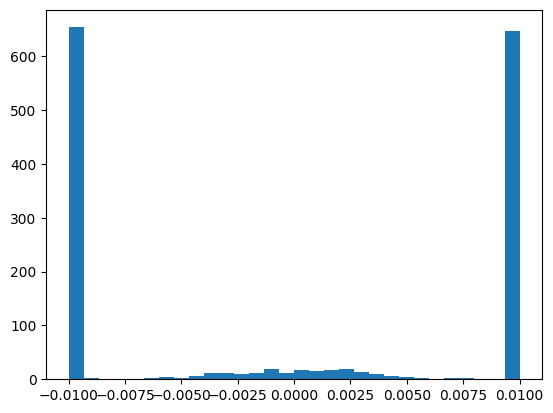

In [ ]:
# SERIALE
D = 2       # dimension of the lattice
L = 10      # size of the lattice

n_simulation = 1000  # number of simulations for averaging
T = 0.8
n_sweep = 100
metropolis_steps = 100 * L**2               # number of Metropolis steps
m_samples = np.zeros(n_simulation)  # array to store magnetization samples

for i in tqdm(range(n_simulation)):
    spin_matrix = np.random.choice([-1, 1], size=(L, L))
    for _ in range(metropolis_steps):
        spin_matrix = Ising_tools.metropolis(spin_matrix, T)
    m_samples[i] = Ising_tools.magnetization(spin_matrix)

plt.hist(m_samples, bins=30, density=True)
plt.title(f'Magnetization Distribution at T={T}')
plt.xlabel('Magnetization')
plt.ylabel('Density')
plt.show()

Tempo di esecuzione con Numba: 0.60 secondi


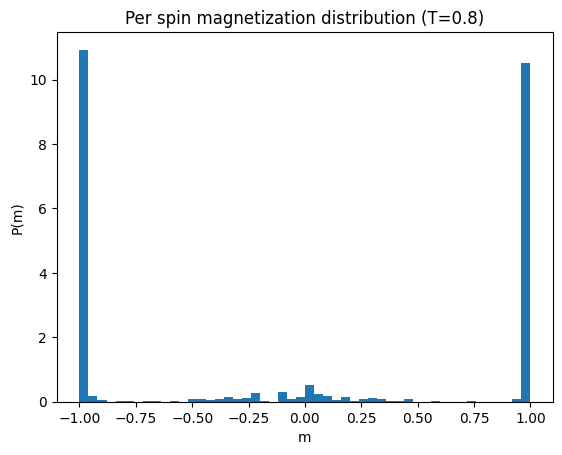

In [18]:
# PARALLELO

# --- PARAMETRI ---
t0 = time.time()
L = 10
n_simulation = 1000
T = 0.8
metropolis_steps = 100 * (L ** 2)
m_samples = np.zeros(n_simulation)

# Warm-up della compilazione JIT
spin_warmup = np.random.choice(np.array([-1, 1]), size=(L, L))
_ = Ising_tools.metropolis_parallel(spin_warmup, T, 1)

# Esecuzione principale
for i in range(n_simulation):
    spin_matrix = np.random.choice(np.array([-1, 1], dtype=np.int8), size=(L, L))
    Ising_tools.metropolis_parallel(spin_matrix, T, metropolis_steps)
    m_samples[i] = Ising_tools.magnetization(spin_matrix)

t1 = time.time()
print(f"Tempo di esecuzione con Numba: {t1 - t0:.2f} secondi")

# --- Istogramma ---
plt.hist(m_samples, bins=50, density=True)
plt.title(f'Per spin magnetization distribution (T={T})')
plt.xlabel('m')
plt.ylabel('P(m)')
plt.show()